In [1]:
# imports 
from optimiseCO import ClosedOrbitFinder
from probes_tune_calc import ProbesTuneCalc
from plot_dat import plot_field_map_and_orbit, plot_r_vs_phi, plot_phase_space, plot_field_map_and_orbit_withprobe
from read_dat import read_trackOrbit, read_trackOrbit, read_FieldMapRPHI, read_FieldMap, read_probe
import numpy as np
import os
import shutil



In [2]:
# check opal is installed correctly
!/home/carl/OPAL/build/src/opal --version

2022.2.99


# Input:

## OPAL's input format is a text file

## I use a python function to write the text file and edit some paramters:

In [3]:
def write_opal_input_file(path, name, num_turns, input_distribution, spiral_angle, trackOrbit=1, FieldMaps=True, D_mag_field=0.502765236428169):
    input_file = f'''\
    //////////////////////////////////////////////////////////////////////////////
    // Input file for single bunch tracking through FETS-FFA ring              //
    //////////////////////////////////////////////////////////////////////////////
    Title,string="FETS-FFA test simulation using OPAL code";
        Option, ASCIIDUMP=TRUE;
        Option, ENABLEHDF5=FALSE;
        OPTION, PSDUMPFREQ=100000;
        Option, VERSION=10900;
        Option, ECHO=FALSE;
        Option, SPTDUMPFREQ={trackOrbit};

    REAL DEGREE=PI/180.;
    REAL MM=1000.;
    REAL C_LIGHT=0.3; // m/ns

    ////////// MODULES ///////////////////////
    BOOL DO_MAGNET_FIELD_MAPS={FieldMaps};


    REAL NUM_TURNS = {num_turns};

    ////////// RING  ///////////////
    REAL R0=4.42;

    REAL E0=12;

    REAL P_MASS=938.272;
    REAL P_CHARGE=1.0;
    REAL P0=((E0+P_MASS)^2-P_MASS^2)^0.5;
    REAL N_CELLS=16;
    REAL RMIN=R0-1.0;
    REAL RMAX=R0+1.0;
    REAL FFA_CELL_LENGTH=2*PI/N_CELLS;
    REAL BFREQ=1;

    ////////// TRACKING ///////////////
    REAL STEP_SIZE=0.01; // m
    REAL BEAM_PHI_INIT=0.0;

    //////// MAIN MAGNETS ////////////////
    REAL CIRCUMFERENCE=8*PI;
    REAL BF=-0.6532097983351404;
    REAL BD={D_mag_field};
    REAL K_VAL=7.717022064259446;


    REAL LAMBDA=0.12;
    REAL SPIRAL_ANGLE={spiral_angle};
    REAL ENGE_0=-1.3;
    REAL ENGE_1=3.42;
    REAL ENGE_2=-1.20;
    REAL ENGE_3=0.23;

    REAL CELL_LENGTH = (2*PI/N_CELLS)*R0;
    REAL AZIMUTHAL_EXTENT=CELL_LENGTH;

    REAL FD_OFFSET = 0.0;

    REAL F_START = (13.5+0.73)*(PI/180)*R0;
    REAL F_CENTRE_LENGTH = (4.5*PI/180)*R0;
    REAL F_END = F_START+F_CENTRE_LENGTH;

    REAL D_START = (2.25-0.73)*(PI/180)*R0;
    REAL D_CENTRE_LENGTH = (2.25*PI/180)*R0;
    REAL D_END =  D_START+D_CENTRE_LENGTH+(0)*(PI/180)*R0;

    ringdef: RINGDEFINITION, HARMONIC_NUMBER=1, LAT_RINIT=R0, LAT_PHIINIT=-6, // =1 for 3MeV
            LAT_THETAINIT=0.0, BEAM_PHIINIT=0.0, BEAM_PRINIT=0.0,
            BEAM_RINIT=0.0, SYMMETRY=16.0, RFFREQ=1, IS_CLOSED=true;

    IF (DO_MAGNET_FIELD_MAPS) {{

        DUMPFIELDS, X_START=-5.0, X_STEPS=708, DX=0.0150, Y_START=-5.0, Y_STEPS=708, DY=0.01500, Z_START=0, Z_STEPS=1, DZ=0.100, FILE_NAME="FieldMapXY.dat";
        DUMPEMFIELDS, COORDINATE_SYSTEM=CYLINDRICAL, R_START=4.0, R_STEPS=1, DR=1.e-3, PHI_START=0., PHI_STEPS=(360/16)*1000, DPHI=1e-3, Z_START=0.01, Z_STEPS=1, DZ=0.100, T_START=0, T_STEPS=1, DT=1., FILE_NAME="FieldMapRPHI.dat";


    }}

    BUILD_PROBE(NAME, ANGLE, DANGLE): MACRO {{
        NAME: PROBE, xstart=RMIN*1000*cos(ANGLE),  xend=RMAX*1000*cos(ANGLE),  ystart=RMIN*1000*sin(ANGLE),  yend=RMAX*1000*sin(ANGLE);
    }}


    REAL THIS_PROBE_PHI=0;
    BUILD_PROBE(Probe1, THIS_PROBE_PHI, 0);
    THIS_PROBE_PHI = EVAL(THIS_PROBE_PHI+FFA_CELL_LENGTH);
    BUILD_PROBE(Probe2, THIS_PROBE_PHI, 0);
    THIS_PROBE_PHI = EVAL(THIS_PROBE_PHI+FFA_CELL_LENGTH);
    BUILD_PROBE(Probe3, THIS_PROBE_PHI, 0);
    THIS_PROBE_PHI = EVAL(THIS_PROBE_PHI+FFA_CELL_LENGTH);
    BUILD_PROBE(Probe4, THIS_PROBE_PHI, 0);
    THIS_PROBE_PHI = EVAL(THIS_PROBE_PHI+FFA_CELL_LENGTH);
    BUILD_PROBE(Probe5, THIS_PROBE_PHI, 0);
    THIS_PROBE_PHI = EVAL(THIS_PROBE_PHI+FFA_CELL_LENGTH);
    BUILD_PROBE(Probe6, THIS_PROBE_PHI, 0);
    THIS_PROBE_PHI = EVAL(THIS_PROBE_PHI+FFA_CELL_LENGTH);
    BUILD_PROBE(Probe7, THIS_PROBE_PHI, 0);
    THIS_PROBE_PHI = EVAL(THIS_PROBE_PHI+FFA_CELL_LENGTH);
    BUILD_PROBE(Probe8, THIS_PROBE_PHI, 0);
    THIS_PROBE_PHI = EVAL(THIS_PROBE_PHI+FFA_CELL_LENGTH);
    BUILD_PROBE(Probe9, THIS_PROBE_PHI, 0);
    THIS_PROBE_PHI = EVAL(THIS_PROBE_PHI+FFA_CELL_LENGTH);
    BUILD_PROBE(Probe10, THIS_PROBE_PHI, 0);
    THIS_PROBE_PHI = EVAL(THIS_PROBE_PHI+FFA_CELL_LENGTH);
    BUILD_PROBE(Probe11, THIS_PROBE_PHI, 0);
    THIS_PROBE_PHI = EVAL(THIS_PROBE_PHI+FFA_CELL_LENGTH);
    BUILD_PROBE(Probe12, THIS_PROBE_PHI, 0);
    THIS_PROBE_PHI = EVAL(THIS_PROBE_PHI+FFA_CELL_LENGTH);
    BUILD_PROBE(Probe13, THIS_PROBE_PHI, 0);
    THIS_PROBE_PHI = EVAL(THIS_PROBE_PHI+FFA_CELL_LENGTH);
    BUILD_PROBE(Probe14, THIS_PROBE_PHI, 0);
    THIS_PROBE_PHI = EVAL(THIS_PROBE_PHI+FFA_CELL_LENGTH);
    BUILD_PROBE(Probe15, THIS_PROBE_PHI, 0);
    THIS_PROBE_PHI = EVAL(THIS_PROBE_PHI+FFA_CELL_LENGTH);
    BUILD_PROBE(Probe16, THIS_PROBE_PHI, 0);
    THIS_PROBE_PHI = EVAL(THIS_PROBE_PHI+FFA_CELL_LENGTH);

    probes: Line = (
        Probe1, Probe2, Probe3, Probe4,
        Probe5, Probe6, Probe7, Probe8,
        Probe9, Probe10, Probe11, Probe12,
        Probe13, Probe14, Probe15, Probe16
    );


    magnet_f_end: ASYMMETRIC_ENGE,
                X0_START=F_CENTRE_LENGTH/2, X0_END=F_CENTRE_LENGTH/2,
                LAMBDA_START=LAMBDA, LAMBDA_END=LAMBDA,
                COEFFICIENTS_START={{ENGE_0, ENGE_1, ENGE_2, ENGE_3}},
                COEFFICIENTS_END={{ENGE_0, ENGE_1, ENGE_2, ENGE_3}};

    f_magnet: ScalingFFAMagnet, B0=BF,
                                R0=R0,
                                FIELD_INDEX=K_VAL,
                                TAN_DELTA=tan(SPIRAL_ANGLE),
                                MAX_Y_POWER=4,
                                END_FIELD_MODEL=magnet_f_end,
                                RADIAL_NEG_EXTENT=0.8,
                                RADIAL_POS_EXTENT=1.2,
                                MAGNET_START=F_START,
                                MAGNET_END=F_END + FD_OFFSET, 
                                HEIGHT=1,
                                AZIMUTHAL_EXTENT=AZIMUTHAL_EXTENT;

    magnet_d_end: ASYMMETRIC_ENGE,
                X0_START=D_CENTRE_LENGTH/2, X0_END=D_CENTRE_LENGTH/2,
                LAMBDA_START=LAMBDA, LAMBDA_END=LAMBDA,
                COEFFICIENTS_START={{ENGE_0, ENGE_1, ENGE_2, ENGE_3}},
                COEFFICIENTS_END={{ENGE_0, ENGE_1, ENGE_2, ENGE_3}};

    d_magnet: ScalingFFAMagnet, B0=BD,
                                R0=R0,
                                FIELD_INDEX=K_VAL,
                                TAN_DELTA=tan(SPIRAL_ANGLE),
                                MAX_Y_POWER=4,
                                END_FIELD_MODEL=magnet_d_end,
                                RADIAL_NEG_EXTENT=0.8,
                                RADIAL_POS_EXTENT=1.2,
                                MAGNET_START=D_START,
                                MAGNET_END=D_END,
                                HEIGHT=1,
                                AZIMUTHAL_EXTENT=AZIMUTHAL_EXTENT;


    cell: Line = (f_magnet, d_magnet);
    l1: Line = (ringdef, probes,
                cell
                );


    REAL B_FREQ=1; // 1 MHz
    REAL SPEED=C_LIGHT*(P0/(E0+P_MASS));
    REAL STEP_SIZE_NS=STEP_SIZE/SPEED;
    REAL STEPS_PER_TURN=1000/STEP_SIZE_NS/B_FREQ; // (this is really steps per B_FREQ)

    Dist1: DISTRIBUTION, TYPE=fromfile, FNAME="{input_distribution}", INPUTMOUNITS=NONE;

    Fs1:FIELDSOLVER, FSTYPE=None, MX=8, MY=8, MT=8,
            PARFFTX=true, PARFFTY=true, PARFFTT=false,
            BCFFTX=open, BCFFTY=open, BCFFTT=open, BBOXINCR=2;
    beam1: BEAM, PARTICLE=PROTON, pc=P0*1e-3, NPART=1, BCURRENT=0, CHARGE=P_CHARGE, mass=P_MASS*1e-3, BFREQ=BFREQ;TRACK, LINE=l1, BEAM=beam1, MAXSTEPS=5000*NUM_TURNS, STEPSPERTURN=STEPS_PER_TURN;

    RUN, METHOD="CYCLOTRON-T", BEAM=beam1, FIELDSOLVER=Fs1, DISTRIBUTION=Dist1;
    ENDTRACK;
    STOP;
    '''
            
    file_path = os.path.join(path, name)
    with open(file_path, "w") as f:
        f.write(input_file)
        


In [4]:
# write input distribution file - just guess 4m as starting coordinate for now
with open(os.path.join(os.getcwd(), "dist.dat"), 'w') as f:
    f.write('1\n') # 1 particle
    f.write(str(4.4)+ ' '+str(0.0)+' '+ str(0.0)+ ' '+str(0.0)+' '+ str(0.0)+' '+ str(0.0))
    f.close()

write_opal_input_file(os.getcwd(), "FD_ffa", num_turns=7, input_distribution="dist.dat", spiral_angle=3.142/4)



# Run OPAL

In [5]:
!/home/carl/OPAL/build/src/opal FD_ffa

OPAL>                ____  _____       ___ 
OPAL>               / __ \|  __ \ /\   | | 
OPAL>              | |  | | |__) /  \  | |
OPAL>              | |  | |  ___/ /\ \ | |
OPAL>              | |__| | |  / ____ \| |____
OPAL>               \____/|_| /_/    \_\______|
OPAL> 
OPAL> This is OPAL (Object Oriented Parallel Accelerator Library) Version 2022.2.99
OPAL>             git rev. e4498781a0cf84f8168cd79231cfe48006423e49
OPAL> 
OPAL> 
OPAL>                      (c) PSI, http://amas.web.psi.ch
OPAL> 
OPAL> 
OPAL> The optimiser (former opt-Pilot) is integrated 
OPAL> 
OPAL> Please send cookies, goodies or other motivations (wine and beer ... ) 
OPAL> to the OPAL developers opal@lists.psi.ch
OPAL> 
OPAL> Time: 13:07:19 date: 15/09/2025
OPAL> 
OPAL> * Reading input stream 'FD_ffa'
Ippl> No solver attached
Ippl> * Creating new file for data: 'FD_ffa.stat'
Ippl> * Creating new file for data: 'FD_ffa.lbal'
OPAL> 
OPAL> * ************* T R A C K  R U N **************************************

## Plot the results

mean radius =  4.405530592326534


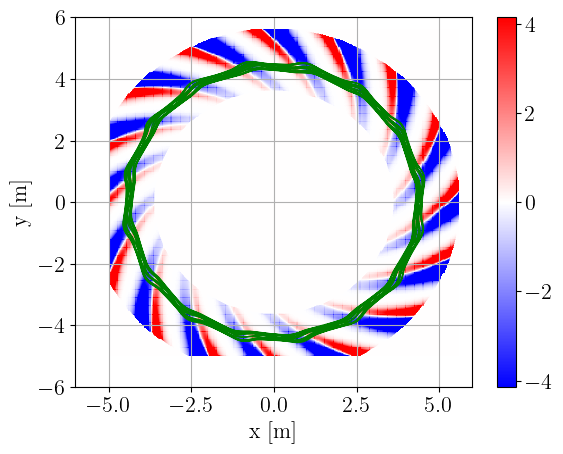

In [6]:
# plot the results
root_path = os.getcwd()
fieldmap_path = os.path.join(root_path, "data/")
track_filename = "FD_ffa" + '-trackOrbit.dat' # the particle position at each time step

fieldmap_filename = "FieldMapXY.dat" # Field maps in XY and R Phi coordinates
fieldmap_cyclindrical_filename =  "FieldMapRPHI.dat"

# read the track orbit
trackOrbit_df = read_trackOrbit(filepath=root_path
                                , filename=track_filename)

#read the field maps
FieldMap_df = read_FieldMap(fieldmap_path, filename=fieldmap_filename)
FieldMapRPHI_df = read_FieldMapRPHI(fieldmap_path, filename=fieldmap_cyclindrical_filename)

#plot
plot_field_map_and_orbit(FieldMap_df, trackOrbit_df)

# The orbit is not closed - ie it doesn't return to the same point at the start/end of each cell

### Use an optimsier to find the closed orbit positon

In [7]:

# now use the closed orbit finder to optimise the inital input distribution to find a closed orbit at this energy

# input dist file for Co at 3MeV
CO_distribution_filename = "CO_coords_12MeV.dat"
    
write_opal_input_file(os.getcwd(), "FD_ffa", num_turns=2, input_distribution=CO_distribution_filename, spiral_angle=3.142/4, trackOrbit=0, FieldMaps=False)


In [8]:
closed_orbit_finder = ClosedOrbitFinder(num_cells=16, input_filepath=os.getcwd(), 
                  input_filename="FD_ffa", distribution_file=CO_distribution_filename)

closed_orbit_finder.main(initial_x=4.42, initial_px=0)

Optimization terminated successfully.6842]  | cell to cell position change =  1.5623300045360424e-08 | Optimisation value =  3.24298941478944349757
         Current function value: 3.242989
         Iterations: 56
         Function evaluations: 117
time taken =  196.03809452056885


([   # x (m)         y (m)   z (m)    px ( )    py ( )  pz ( )  id  turn ( )  \
  0  4.39525  0.000000e+00       0  0.016268  0.160445       0   0         1   
  1  4.39525  0.000000e+00       0  0.016268  0.160445       0   0         1   
  2  4.39523  4.336810e-19       0  0.016271  0.160444       0   0         1   
  3  4.39525 -8.673620e-19       0  0.016269  0.160445       0   0         2   
  4  4.39523 -2.168400e-19       0  0.016269  0.160445       0   0         2   
  
     bunchNumber ( )      time (s)  
  0                0  0.000000e+00  
  1                0  0.000000e+00  
  2                0  5.875990e-07  
  3                0  1.175200e-06  
  4                0  1.762800e-06  ,
     # x (m)    y (m)   z (m)    px ( )    py ( )  pz ( )  id  turn ( )  \
  0  4.06067  1.68198       0 -0.046369  0.154457       0   0         1   
  1  4.06068  1.68199       0 -0.046367  0.154458       0   0         1   
  2  4.06068  1.68199       0 -0.046370  0.154457       0   0        

OPAL>                ____  _____       ___ 
OPAL>               / __ \|  __ \ /\   | | 
OPAL>              | |  | | |__) /  \  | |
OPAL>              | |  | |  ___/ /\ \ | |
OPAL>              | |__| | |  / ____ \| |____
OPAL>               \____/|_| /_/    \_\______|
OPAL> 
OPAL> This is OPAL (Object Oriented Parallel Accelerator Library) Version 2022.2.99
OPAL>             git rev. e4498781a0cf84f8168cd79231cfe48006423e49
OPAL> 
OPAL> 
OPAL>                      (c) PSI, http://amas.web.psi.ch
OPAL> 
OPAL> 
OPAL> The optimiser (former opt-Pilot) is integrated 
OPAL> 
OPAL> Please send cookies, goodies or other motivations (wine and beer ... ) 
OPAL> to the OPAL developers opal@lists.psi.ch
OPAL> 
OPAL> Time: 13:10:53 date: 15/09/2025
OPAL> 
OPAL> * Reading input stream 'FD_ffa'
Ippl> No solver attached
Ippl> * Creating new file for data: 'FD_ffa.stat'
Ippl> * Creating new file for data: 'FD_ffa.lbal'
OPAL> 
OPAL> * ************* T R A C K  R U N **************************************

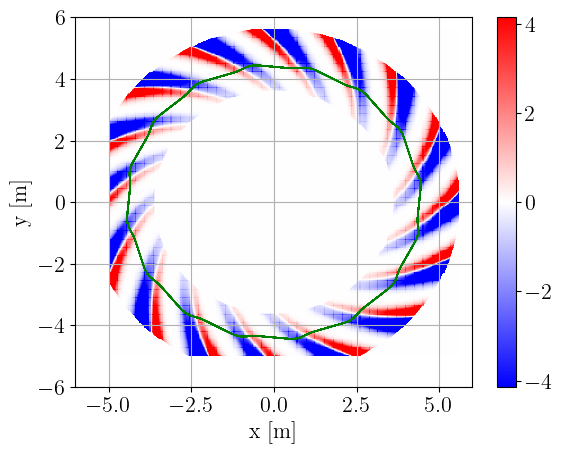

path to closed orbit probes =  /home/carl/Documents/FFA25-school/co_dir/


In [9]:
write_opal_input_file(os.getcwd(), "FD_ffa", num_turns=10, input_distribution=CO_distribution_filename, spiral_angle=3.142/4, trackOrbit=1, FieldMaps=False)

!/home/carl/OPAL/build/src/opal FD_ffa

# plot the results
root_path = os.getcwd()
fieldmap_path = os.path.join(root_path, "data/")
track_filename = "FD_ffa" + '-trackOrbit.dat' # the particle position at each time step

fieldmap_filename = "FieldMapXY.dat" # Field maps in XY and R Phi coordinates
fieldmap_cyclindrical_filename =  "FieldMapRPHI.dat"

# read the track orbit
trackOrbit_df = read_trackOrbit(filepath=root_path
                                , filename=track_filename)

#read the field maps
FieldMap_df = read_FieldMap(fieldmap_path, filename=fieldmap_filename)
FieldMapRPHI_df = read_FieldMapRPHI(fieldmap_path, filename=fieldmap_cyclindrical_filename)

#plot
plot_field_map_and_orbit(FieldMap_df, trackOrbit_df)

path = os.getcwd()
path_to_closed_orbit_probes = os.path.join(path,"co_dir/")
print("path to closed orbit probes = ",path_to_closed_orbit_probes)
if not os.path.isdir(path_to_closed_orbit_probes):
    os.mkdir(path_to_closed_orbit_probes)
    
for x in os.listdir(path):
    if x.endswith(".loss"):
        shutil.copyfile(x, path_to_closed_orbit_probes+x) 

# Calculate the Tune

In [10]:
# view the closed orbit coords the optimiser arrived at

with open(CO_distribution_filename) as f:
    lines = f.readlines()
    f.close()
vals = lines[1].split()
co_xcoords = float(vals[0])
co_pxcoords = float(vals[1])
print(co_xcoords)
print(co_pxcoords)

4.395245598494839
0.016268421156887713


## Run 50 Turns of the closed orbit trajectory

In [11]:
write_opal_input_file(os.getcwd(), "FD_ffa", num_turns=50, input_distribution=CO_distribution_filename, spiral_angle=3.142/4, trackOrbit=0, FieldMaps=False)

# Run opal , info 0 suppresses the text output
!/home/carl/OPAL/build/src/opal --info 0 FD_ffa 
print("Done")

Done


# make a new input distribution file 

In [12]:
# write input distribution file - just guess 4m as starting coordinate for now
perturbed_dist_file = "perturbed_coords_12MeV.dat"
with open(os.path.join(os.getcwd(), perturbed_dist_file), 'w') as f:
    f.write('1\n') # 1 particle
    # offset my 1mm in x and z from the closed orbit
    f.write(str(co_xcoords + 1e-3)+ ' '+str(co_pxcoords)+' '+ str(0.0)+ ' '+str(0.0)+' '+ str(0.0 + 1e-3)+' '+ str(0.0))
    f.close()


## Run 50 turns of a particle perturbed from the closed orbit

In [13]:
write_opal_input_file(os.getcwd(), "FD_ffa", num_turns=50, input_distribution=perturbed_dist_file, spiral_angle=3.142/4, trackOrbit=1, FieldMaps=False)

!/home/carl/OPAL/build/src/opal --info 0 FD_ffa
print("Done")

Done


mean radius =  4.418917950292261


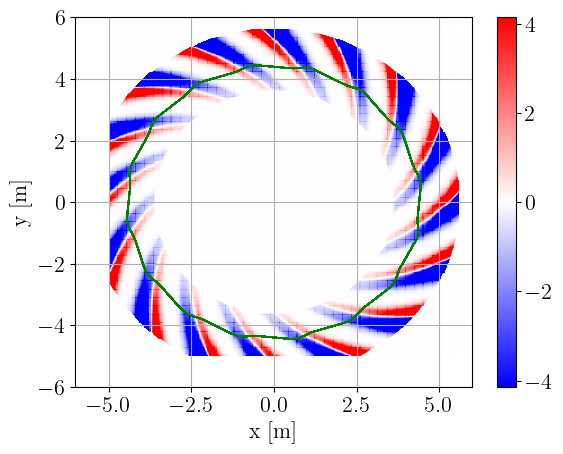

In [14]:
# read the track orbit
trackOrbit_df = read_trackOrbit(filepath=root_path
                                , filename=track_filename)

#read the field maps
FieldMap_df = read_FieldMap(fieldmap_path, filename=fieldmap_filename)
FieldMapRPHI_df = read_FieldMapRPHI(fieldmap_path, filename=fieldmap_cyclindrical_filename)

#plot
plot_field_map_and_orbit(FieldMap_df, trackOrbit_df)

## Finally, can calculate the tune using PyNaff

In [15]:
# now finally calculate the tunes using the closed orbit probes and the probes from the perturbed particle 

print("path to closed orbit probes = ",path_to_closed_orbit_probes)
n_cells = 16
tunex , tunez = ProbesTuneCalc(n_cells, os.getcwd(), path_to_closed_orbit_probes).main(naff=True)

print(f"Horizontal tune {tunex[0]*n_cells} | Vertical tune {tunez[0]*n_cells} ")

path to closed orbit probes =  /home/carl/Documents/FFA25-school/co_dir/
number of particles =  1
num_lost_particles =  0
Using NAFF
cell tunex, =  [np.float64(0.21319265240390395)]
cell tunez =  [np.float64(0.21192067221289232)]
Horizontal tune 3.411082438462463 | Vertical tune 3.390730755406277 


# Modifying the lattice

## change the spiral angle and D magnet

In [16]:
write_opal_input_file(os.getcwd(), "FD_ffa", num_turns=6, input_distribution=CO_distribution_filename, \
                          spiral_angle=55*np.pi/180, trackOrbit=1, FieldMaps=True, D_mag_field=0)

!/home/carl/OPAL/build/src/opal FD_ffa

OPAL>                ____  _____       ___ 
OPAL>               / __ \|  __ \ /\   | | 
OPAL>              | |  | | |__) /  \  | |
OPAL>              | |  | |  ___/ /\ \ | |
OPAL>              | |__| | |  / ____ \| |____
OPAL>               \____/|_| /_/    \_\______|
OPAL> 
OPAL> This is OPAL (Object Oriented Parallel Accelerator Library) Version 2022.2.99
OPAL>             git rev. e4498781a0cf84f8168cd79231cfe48006423e49
OPAL> 
OPAL> 
OPAL>                      (c) PSI, http://amas.web.psi.ch
OPAL> 
OPAL> 
OPAL> The optimiser (former opt-Pilot) is integrated 
OPAL> 
OPAL> Please send cookies, goodies or other motivations (wine and beer ... ) 
OPAL> to the OPAL developers opal@lists.psi.ch
OPAL> 
OPAL> Time: 13:12:31 date: 15/09/2025
OPAL> 
OPAL> * Reading input stream 'FD_ffa'
Ippl> No solver attached
Ippl> * Creating new file for data: 'FD_ffa.stat'
Ippl> * Creating new file for data: 'FD_ffa.lbal'
OPAL> 
OPAL> * ************* T R A C K  R U N **************************************

mean radius =  4.144553698096703


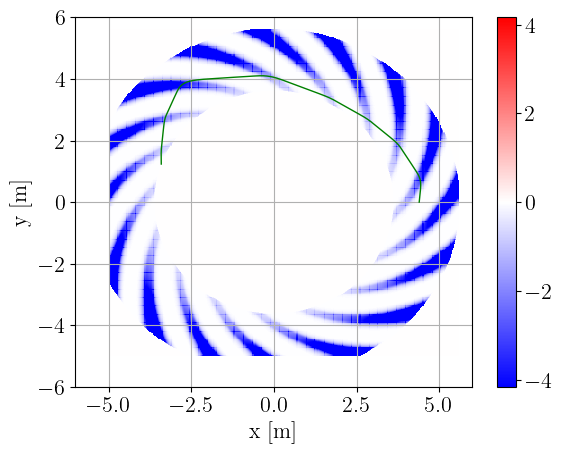

In [17]:
# read the track orbit
trackOrbit_df = read_trackOrbit(filepath=root_path
                                , filename=track_filename)

#read the field maps
FieldMap_df = read_FieldMap(fieldmap_path, filename=fieldmap_filename)
FieldMapRPHI_df = read_FieldMapRPHI(fieldmap_path, filename=fieldmap_cyclindrical_filename)

#plot
plot_field_map_and_orbit(FieldMap_df, trackOrbit_df)

## Find new closed orbit and tunes

In [18]:
write_opal_input_file(os.getcwd(), "FD_ffa", num_turns=2, input_distribution=CO_distribution_filename, \
                          spiral_angle=55*np.pi/180, trackOrbit=0, FieldMaps=False, D_mag_field=0)

closed_orbit_finder = ClosedOrbitFinder(num_cells=16, input_filepath=os.getcwd(), 
                  input_filename="FD_ffa", distribution_file=CO_distribution_filename)

closed_orbit_finder.main(initial_x=4.42, initial_px=0)


path = os.getcwd()
path_to_closed_orbit_probes = os.path.join(path,"co_dir/")
print("path to closed orbit probes = ",path_to_closed_orbit_probes)
if not os.path.isdir(path_to_closed_orbit_probes):
    os.mkdir(path_to_closed_orbit_probes)
    
for x in os.listdir(path):
    if x.endswith(".loss"):
        shutil.copyfile(x, path_to_closed_orbit_probes+x) 


with open(CO_distribution_filename) as f:
    lines = f.readlines()
    f.close()
vals = lines[1].split()
co_xcoords = float(vals[0])
co_pxcoords = float(vals[1])
print(co_xcoords)
print(co_pxcoords)


write_opal_input_file(os.getcwd(), "FD_ffa", num_turns=50, input_distribution=CO_distribution_filename, \
                          spiral_angle=55*np.pi/180, trackOrbit=0, FieldMaps=False, D_mag_field=0)
!/home/carl/OPAL/build/src/opal --info 0 FD_ffa
print("Done")

# write input distribution file - just guess 4m as starting coordinate for now
perturbed_dist_file = "perturbed_coords_12MeV.dat"
with open(os.path.join(os.getcwd(), perturbed_dist_file), 'w') as f:
    f.write('1\n') # 1 particle
    # offset my 1mm in x and z from the closed orbit
    f.write(str(co_xcoords + 1e-3)+ ' '+str(co_pxcoords)+' '+ str(0.0)+ ' '+str(0.0)+' '+ str(0.0 + 1e-3)+' '+ str(0.0))
    f.close()



write_opal_input_file(os.getcwd(), "FD_ffa", num_turns=50, input_distribution=perturbed_dist_file, spiral_angle=55*np.pi/180, trackOrbit=1, FieldMaps=False,D_mag_field=0)

!/home/carl/OPAL/build/src/opal FD_ffa


n_cells = 16
tunex , tunez = ProbesTuneCalc(n_cells, os.getcwd(), path_to_closed_orbit_probes).main(naff=True)

print(f"Horizontal tune {tunex[0]*n_cells} | Vertical tune {tunez[0]*n_cells} ")

Optimiser input =  [4.17313191 0.02486448]  | cell to cell position change =  6433567018538069.0 | Optimisation value =  955990192.40004313754927213

--------------------------------------------------------------------------
MPI_ABORT was invoked on rank 0 in communicator MPI_COMM_WORLD
with errorcode -100.

NOTE: invoking MPI_ABORT causes Open MPI to kill all MPI processes.
You may or may not see output from other processes, depending on
exactly when Open MPI kills them.
--------------------------------------------------------------------------


Optimization terminated successfully.1807]  | cell to cell position change =  1.0205801401134631e-07 | Optimisation value =  3.2461775261629184
         Current function value: 3.246177
         Iterations: 58
         Function evaluations: 113
time taken =  169.58384084701538
path to closed orbit probes =  /home/carl/Documents/FFA25-school/co_dir/
4.16569613767952
0.017618069640644725
Done
OPAL>                ____  _____       ___ 
OPAL>               / __ \|  __ \ /\   | | 
OPAL>              | |  | | |__) /  \  | |
OPAL>              | |  | |  ___/ /\ \ | |
OPAL>              | |__| | |  / ____ \| |____
OPAL>               \____/|_| /_/    \_\______|
OPAL> 
OPAL> This is OPAL (Object Oriented Parallel Accelerator Library) Version 2022.2.99
OPAL>             git rev. e4498781a0cf84f8168cd79231cfe48006423e49
OPAL> 
OPAL> 
OPAL>                      (c) PSI, http://amas.web.psi.ch
OPAL> 
OPAL> 
OPAL> The optimiser (former opt-Pilot) is integrated 
OPAL> 
OPAL> Please send cookies, goo

mean radius =  4.157443081808815


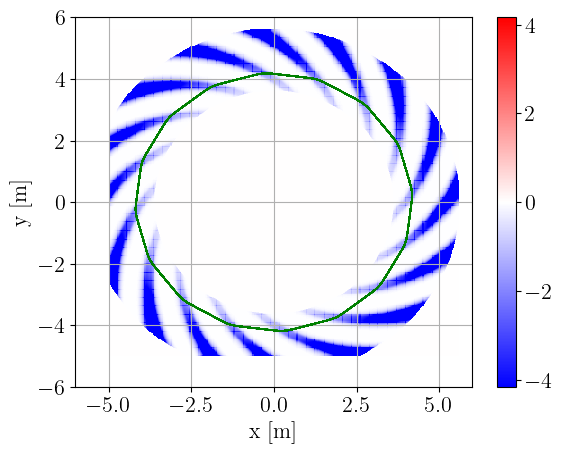

In [19]:
trackOrbit_df = read_trackOrbit(filepath=root_path
                                , filename=track_filename)

#read the field maps
FieldMap_df = read_FieldMap(fieldmap_path, filename=fieldmap_filename)
FieldMapRPHI_df = read_FieldMapRPHI(fieldmap_path, filename=fieldmap_cyclindrical_filename)

#plot
plot_field_map_and_orbit(FieldMap_df, trackOrbit_df)

# Four fold symmetry lattice

In [20]:
def write_opal_input_file_four_fold(path, name, num_turns, input_distribution, spiral_angle=np.pi/6, trackOrbit=1, FieldMaps=True):
    input_file = f'''
    
    //////////////////////////////////////////////////////////////////////////////
    // Input file for single bunch tracking through FETS-FFA ring              //
    //////////////////////////////////////////////////////////////////////////////
    Title,string="FETS-FFA test simulation using OPAL code";
        Option, ASCIIDUMP=TRUE;
        Option, ENABLEHDF5=FALSE;
        OPTION, PSDUMPFREQ=100000;
        Option, VERSION=10900;
    
        Option, ECHO=FALSE;
    
        Option, SPTDUMPFREQ={trackOrbit};
    
    ////////// CONSTANTS ////////////////////////////////////
    // * "Length" is total length of the sector magnet
    // * each coil has centre length = Length/n * 0.8
    
    REAL DEGREE=PI/180.;
    REAL MM=1000.;
    REAL C_LIGHT=0.3; // m/ns
    
    ////////// MODULES ///////////////////////
    BOOL DO_MAGNET_FIELD_MAPS={FieldMaps};

    REAL NUM_TURNS = {num_turns};
    
    ////////// RING  ///////////////
    REAL R0=4.0;
    
    REAL E0=3;
    
    REAL P_MASS=938.272;
    REAL P_CHARGE=1.0;
    REAL P0=((E0+P_MASS)^2-P_MASS^2)^0.5;
    REAL N_CELLS=16;
    REAL CURRENT=1.6e-19;
    REAL RMIN=R0-1.0;
    REAL RMAX=R0+1.0;
    REAL FFA_CELL_LENGTH=2*PI/N_CELLS;
    REAL BFREQ=1;
    
    ////////// TRACKING ///////////////
    REAL STEP_SIZE=0.01; // m
    REAL BEAM_PHI_INIT=0.0;
    
    //////// MAIN MAGNETS ////////////////
    REAL K_VAL=7.4319;
    
    
    REAL LAMBDA=0.14;
    REAL SPIRAL_ANGLE={spiral_angle};
    REAL ENGE_0=0;
    REAL ENGE_1=3.91;
    
    REAL CELL_LENGTH = (2*PI/N_CELLS)*R0;
    REAL AZIMUTHAL_EXTENT=CELL_LENGTH;
    
    REAL CELL_LENGTH_ANGULAR = 2*PI/16;
    
    REAL BF1_START = 0; // RAD IN BRACKETS, ALL * R0 TO CONVERT TO METERS
    REAL BF1_CENTRE_LENGTH = (0.2*CELL_LENGTH_ANGULAR)*R0;
    REAL BF1_END = BF1_CENTRE_LENGTH;
    
    REAL BD1_START = (0.1*CELL_LENGTH_ANGULAR)*R0;
    REAL BD1_CENTRE_LENGTH = (0.1*CELL_LENGTH_ANGULAR)*R0;
    REAL BD1_END = BD1_START+BD1_CENTRE_LENGTH+(0.6*CELL_LENGTH_ANGULAR -0.0125)*R0;
    
    REAL BF2_START = 0;
    REAL BF2_CENTRE_LENGTH = (0.2*CELL_LENGTH_ANGULAR)*R0;
    REAL BF2_END = BF2_CENTRE_LENGTH;
    
    REAL BD2_START = (0.1*CELL_LENGTH_ANGULAR)*R0;
    REAL BD2_CENTRE_LENGTH = (0.1*CELL_LENGTH_ANGULAR)*R0;
    REAL BD2_END = BD2_START+BD2_CENTRE_LENGTH+(0.6*CELL_LENGTH_ANGULAR -0.125)*R0;
    
    REAL BF3_START = 0;
    REAL BF3_CENTRE_LENGTH = (0.2*CELL_LENGTH_ANGULAR)*R0;
    REAL BF3_END = BF3_CENTRE_LENGTH;
    
    REAL BD3_START = (0.1*CELL_LENGTH_ANGULAR)*R0;
    REAL BD3_CENTRE_LENGTH = (0.1*CELL_LENGTH_ANGULAR)*R0;
    REAL BD3_END = BD3_START+BD3_CENTRE_LENGTH+(0.6*CELL_LENGTH_ANGULAR -0.0125)*R0;
    
    REAL BF4_START = 0;
    REAL BF4_CENTRE_LENGTH = (0.2*CELL_LENGTH_ANGULAR)*R0;
    REAL BF4_END =BF4_CENTRE_LENGTH;
    
    REAL BD4_START = (0.1*CELL_LENGTH_ANGULAR)*R0;
    REAL BD4_CENTRE_LENGTH = (0.1*CELL_LENGTH_ANGULAR)*R0;
    REAL BD4_END = BD4_START+BD4_CENTRE_LENGTH+((0.6*CELL_LENGTH_ANGULAR + 0.15)/2)*R0*2;
    
    ringdef: RINGDEFINITION, HARMONIC_NUMBER=1, LAT_RINIT=4.0, LAT_PHIINIT=((0.6*CELL_LENGTH_ANGULAR + 0.15)/2)*180/PI,
            LAT_THETAINIT=0.0, BEAM_PHIINIT=0.0, BEAM_PRINIT=0.0,
            BEAM_RINIT=0.0, SYMMETRY=4.0, RFFREQ=1, IS_CLOSED=true;
    
    IF (DO_MAGNET_FIELD_MAPS) {{
    
        DUMPFIELDS, X_START=-5.0, X_STEPS=708, DX=0.0150, Y_START=-5.0, Y_STEPS=708, DY=0.01500, Z_START=0, Z_STEPS=1, DZ=0.100, FILE_NAME="FieldMapXY.dat";
        DUMPEMFIELDS, COORDINATE_SYSTEM=CYLINDRICAL, R_START=4.0, R_STEPS=1, DR=1.e-3, PHI_START=0., PHI_STEPS=(360/16)*1000, DPHI=1e-3, Z_START=0.01, Z_STEPS=1, DZ=0.100, T_START=0, T_STEPS=1, DT=1., FILE_NAME="FieldMapRPHI.dat";
    
    }}
    
    BUILD_PROBE(NAME, ANGLE, DANGLE): MACRO {{
        NAME: PROBE, xstart=RMIN*1000*cos(ANGLE),  xend=RMAX*1000*cos(ANGLE),  ystart=RMIN*1000*sin(ANGLE),  yend=RMAX*1000*sin(ANGLE);
    }}
    
    
    REAL THIS_PROBE_PHI=0.0;
    BUILD_PROBE(Probe1, THIS_PROBE_PHI, 0);
    THIS_PROBE_PHI = EVAL(THIS_PROBE_PHI+PI/2);
    BUILD_PROBE(Probe2, THIS_PROBE_PHI, 0);
    THIS_PROBE_PHI = EVAL(THIS_PROBE_PHI+PI/2);
    BUILD_PROBE(Probe3, THIS_PROBE_PHI, 0);
    THIS_PROBE_PHI = EVAL(THIS_PROBE_PHI+PI/2);
    BUILD_PROBE(Probe4, THIS_PROBE_PHI, 0);
    THIS_PROBE_PHI = EVAL(THIS_PROBE_PHI+PI/2);
    
    probes: Line = (
        Probe1, Probe2, Probe3, Probe4
    );
    
    
    magnet_bf1_end: ASYMMETRIC_ENGE,
                X0_START=BF1_CENTRE_LENGTH/2, X0_END=BF1_CENTRE_LENGTH/2,
                LAMBDA_START=LAMBDA, LAMBDA_END=LAMBDA,
                COEFFICIENTS_START={{ENGE_0,ENGE_1}},
                COEFFICIENTS_END={{ENGE_0,ENGE_1}};
    
    bf1_magnet: ScalingFFAMagnet, B0=-0.370973,
                                R0=R0,
                                FIELD_INDEX=K_VAL,
                                TAN_DELTA=tan(SPIRAL_ANGLE),
                                MAX_Y_POWER=4,
                                END_FIELD_MODEL=magnet_bf1_end,
                                RADIAL_NEG_EXTENT=0.15,
                                RADIAL_POS_EXTENT=0.8,
                                MAGNET_START=BF1_START,
                                MAGNET_END=BF1_END, 
                                HEIGHT=1,
                                AZIMUTHAL_EXTENT=AZIMUTHAL_EXTENT;
    
    magnet_bd1_end: ASYMMETRIC_ENGE,
                X0_START=BD1_CENTRE_LENGTH/2, X0_END=BD1_CENTRE_LENGTH/2,
                LAMBDA_START=LAMBDA, LAMBDA_END=LAMBDA,
                COEFFICIENTS_START={{ENGE_0,ENGE_1}},
                COEFFICIENTS_END={{ENGE_0,ENGE_1}};
    
    bd1_magnet: ScalingFFAMagnet, B0=0.364563,
                                R0=R0,
                                FIELD_INDEX=K_VAL,
                                TAN_DELTA=tan(SPIRAL_ANGLE),
                                MAX_Y_POWER=4,
                                END_FIELD_MODEL=magnet_bd1_end,
                                RADIAL_NEG_EXTENT=0.15,
                                RADIAL_POS_EXTENT=0.8,
                                MAGNET_START=BD1_START,
                                MAGNET_END=BD1_END,
                                HEIGHT=1,
                                AZIMUTHAL_EXTENT=AZIMUTHAL_EXTENT;
    
                                
    
    magnet_bf2_end: ASYMMETRIC_ENGE,
                X0_START=BF2_CENTRE_LENGTH/2, X0_END=BF2_CENTRE_LENGTH/2,
                LAMBDA_START=LAMBDA, LAMBDA_END=LAMBDA,
                COEFFICIENTS_START={{ENGE_0,ENGE_1}},
                COEFFICIENTS_END={{ENGE_0,ENGE_1}};
    
    bf2_magnet: ScalingFFAMagnet, B0=-0.314173 ,
                                R0=R0,
                                FIELD_INDEX=K_VAL,
                                TAN_DELTA=tan(SPIRAL_ANGLE),
                                MAX_Y_POWER=4,
                                END_FIELD_MODEL=magnet_bf2_end,
                                RADIAL_NEG_EXTENT=0.15,
                                RADIAL_POS_EXTENT=0.8,
                                MAGNET_START=BF2_START,
                                MAGNET_END=BF2_END, 
                                HEIGHT=1,
                                AZIMUTHAL_EXTENT=AZIMUTHAL_EXTENT;
    
    magnet_bd2_end: ASYMMETRIC_ENGE,
                X0_START=BD2_CENTRE_LENGTH/2, X0_END=BD2_CENTRE_LENGTH/2,
                LAMBDA_START=LAMBDA, LAMBDA_END=LAMBDA,
                COEFFICIENTS_START={{ENGE_0,ENGE_1}},
                COEFFICIENTS_END={{ENGE_0,ENGE_1}};
    
    bd2_magnet: ScalingFFAMagnet, B0=0.330844,
                                R0=R0,
                                FIELD_INDEX=K_VAL,
                                TAN_DELTA=tan(SPIRAL_ANGLE),
                                MAX_Y_POWER=4,
                                END_FIELD_MODEL=magnet_bd2_end,
                                RADIAL_NEG_EXTENT=0.15,
                                RADIAL_POS_EXTENT=0.8,
                                MAGNET_START=BD2_START,
                                MAGNET_END=BD2_END,
                                HEIGHT=1,
                                AZIMUTHAL_EXTENT=AZIMUTHAL_EXTENT;
             
    
    magnet_bf3_end: ASYMMETRIC_ENGE,
                X0_START=BF3_CENTRE_LENGTH/2, X0_END=BF3_CENTRE_LENGTH/2,
                LAMBDA_START=LAMBDA, LAMBDA_END=LAMBDA,
                COEFFICIENTS_START={{ENGE_0,ENGE_1}},
                COEFFICIENTS_END={{ENGE_0,ENGE_1}};
    
    bf3_magnet: ScalingFFAMagnet, B0=-0.338564,
                                R0=R0,
                                FIELD_INDEX=K_VAL,
                                TAN_DELTA=tan(SPIRAL_ANGLE),
                                MAX_Y_POWER=4,
                                END_FIELD_MODEL=magnet_bf3_end,
                                RADIAL_NEG_EXTENT=0.15,
                                RADIAL_POS_EXTENT=0.8,
                                MAGNET_START=BF3_START,
                                MAGNET_END=BF3_END, 
                                HEIGHT=1,
                                AZIMUTHAL_EXTENT=AZIMUTHAL_EXTENT;
    
    magnet_bd3_end: ASYMMETRIC_ENGE,
                X0_START=BD3_CENTRE_LENGTH/2, X0_END=BD3_CENTRE_LENGTH/2,
                LAMBDA_START=LAMBDA, LAMBDA_END=LAMBDA,
                COEFFICIENTS_START={{ENGE_0,ENGE_1}},
                COEFFICIENTS_END={{ENGE_0,ENGE_1}};
    
    bd3_magnet: ScalingFFAMagnet, B0=0.369984,
                                R0=R0,
                                FIELD_INDEX=K_VAL,
                                TAN_DELTA=tan(SPIRAL_ANGLE),
                                MAX_Y_POWER=4,
                                END_FIELD_MODEL=magnet_bd3_end,
                                RADIAL_NEG_EXTENT=0.15,
                                RADIAL_POS_EXTENT=0.8,
                                MAGNET_START=BD3_START,
                                MAGNET_END=BD3_END,
                                HEIGHT=1,
                                AZIMUTHAL_EXTENT=AZIMUTHAL_EXTENT;
    
    
    magnet_bf4_end: ASYMMETRIC_ENGE,
                X0_START=BF4_CENTRE_LENGTH/2, X0_END=BF4_CENTRE_LENGTH/2,
                LAMBDA_START=LAMBDA, LAMBDA_END=LAMBDA,
                COEFFICIENTS_START={{ENGE_0,ENGE_1}},
                COEFFICIENTS_END={{ENGE_0,ENGE_1}};
    
    bf4_magnet: ScalingFFAMagnet, B0=-0.434163,
                                R0=R0,
                                FIELD_INDEX=K_VAL,
                                TAN_DELTA=tan(SPIRAL_ANGLE),
                                MAX_Y_POWER=4,
                                END_FIELD_MODEL=magnet_bf4_end,
                                RADIAL_NEG_EXTENT=0.15,
                                RADIAL_POS_EXTENT=0.8,
                                MAGNET_START=BF4_START,
                                MAGNET_END=BF4_END, 
                                HEIGHT=1,
                                AZIMUTHAL_EXTENT=AZIMUTHAL_EXTENT;
    
    magnet_bd4_end: ASYMMETRIC_ENGE,
                X0_START=BD4_CENTRE_LENGTH/2, X0_END=BD4_CENTRE_LENGTH/2,
                LAMBDA_START=LAMBDA, LAMBDA_END=LAMBDA,
                COEFFICIENTS_START={{ENGE_0,ENGE_1}},
                COEFFICIENTS_END={{ENGE_0,ENGE_1}};
    
    bd4_magnet: ScalingFFAMagnet, B0=0.464282,
                                R0=R0,
                                FIELD_INDEX=K_VAL,
                                TAN_DELTA=tan(SPIRAL_ANGLE),
                                MAX_Y_POWER=4,
                                END_FIELD_MODEL=magnet_bd4_end,
                                RADIAL_NEG_EXTENT=0.15,
                                RADIAL_POS_EXTENT=0.8,
                                MAGNET_START=BD4_START,
                                MAGNET_END=BD4_END,
                                HEIGHT=1,
                                AZIMUTHAL_EXTENT=AZIMUTHAL_EXTENT;
    
    
    cell: Line = (bf1_magnet, bd1_magnet, bf2_magnet, bd2_magnet, bf3_magnet, bd3_magnet, bf4_magnet, bd4_magnet);
    l1: Line = (ringdef, probes,
                cell);
    
    REAL B_FREQ=1; // 1 MHz
    REAL SPEED=C_LIGHT*(P0/(E0+P_MASS));
    REAL STEP_SIZE_NS=STEP_SIZE/SPEED;
    REAL STEPS_PER_TURN=1000/STEP_SIZE_NS/B_FREQ; // (this is really steps per B_FREQ)
    
    Dist1: DISTRIBUTION, TYPE=fromfile, FNAME="{input_distribution}", INPUTMOUNITS=NONE;

    Fs1:FIELDSOLVER, FSTYPE=None, MX=8, MY=8, MT=8,
            PARFFTX=true, PARFFTY=true, PARFFTT=false,
            BCFFTX=open, BCFFTY=open, BCFFTT=open, BBOXINCR=2;
    beam1: BEAM, PARTICLE=PROTON, pc=P0*1e-3, NPART=1, BCURRENT=0, CHARGE=P_CHARGE, mass=P_MASS*1e-3, BFREQ=BFREQ;TRACK, LINE=l1, BEAM=beam1, MAXSTEPS=5000*NUM_TURNS, STEPSPERTURN=STEPS_PER_TURN;

    RUN, METHOD="CYCLOTRON-T", BEAM=beam1, FIELDSOLVER=Fs1, DISTRIBUTION=Dist1;
    ENDTRACK;
    STOP;
    '''

    file_path = os.path.join(path, name)
    with open(file_path, "w") as f:
        f.write(input_file)
        

## Find the closed orbit and tune for the four fold symmetry lattice.

In [21]:
CO_distribution_filename_four_fold = "CO_coords_3MeV_four_fold.dat"


write_opal_input_file_four_fold(os.getcwd(), "FD_ffa_four_fold", num_turns=2, input_distribution=CO_distribution_filename_four_fold, \
                          trackOrbit=0, FieldMaps=False)


closed_orbit_finder = ClosedOrbitFinder(num_cells=4, input_filepath=os.getcwd(), 
                  input_filename="FD_ffa_four_fold", distribution_file=CO_distribution_filename_four_fold)

closed_orbit_finder.main(initial_x=4.0, initial_px=0.0)




with open(CO_distribution_filename_four_fold) as f:
    lines = f.readlines()
    f.close()
vals = lines[1].split()
co_xcoords = float(vals[0])
co_pxcoords = float(vals[1])
print(co_xcoords)
print(co_pxcoords)


write_opal_input_file_four_fold(os.getcwd(), "FD_ffa_four_fold", num_turns=50, input_distribution=CO_distribution_filename_four_fold, \
                        trackOrbit=0, FieldMaps=False)
!/home/carl/OPAL/build/src/opal --info 0 FD_ffa_four_fold
print("Done")

path = os.getcwd()
path_to_closed_orbit_probes = os.path.join(path,"co_dir_fourfold/")
print("path to closed orbit probes = ",path_to_closed_orbit_probes)
if not os.path.isdir(path_to_closed_orbit_probes):
    os.mkdir(path_to_closed_orbit_probes)
    
for x in os.listdir(path):
    if x.endswith(".loss"):
        shutil.copyfile(x, path_to_closed_orbit_probes+x) 


# write input distribution file - just guess 4m as starting coordinate for now
perturbed_dist_four_fold = "perturbed_coords_3MeV_four_fold.dat"
with open(os.path.join(os.getcwd(), perturbed_dist_four_fold), 'w') as f:
    f.write('1\n') # 1 particle
    # offset my 1mm in x and z from the closed orbit
    f.write(str(co_xcoords + 1e-3)+ ' '+str(co_pxcoords)+' '+ str(0.0)+ ' '+str(0.0)+' '+ str(0.0 + 1e-3)+' '+ str(0.0))
    f.close()



write_opal_input_file_four_fold(os.getcwd(), "FD_ffa_four_fold", num_turns=50, input_distribution=perturbed_dist_four_fold, trackOrbit=1, FieldMaps=True)

!/home/carl/OPAL/build/src/opal FD_ffa_four_fold


n_cells = 4
tunex , tunez = ProbesTuneCalc(n_cells, os.getcwd(), path_to_closed_orbit_probes).main(naff=True)

print(f"Horizontal tune {(1-tunex[0])*n_cells} | Vertical tune {(1-tunez[0])*n_cells} ")

Optimiser input =  [3.95292969 0.01376184]  | cell to cell position change =  6915391873093561.0 | Optimisation value =  219746864.232533163444945743

--------------------------------------------------------------------------
MPI_ABORT was invoked on rank 0 in communicator MPI_COMM_WORLD
with errorcode -100.

NOTE: invoking MPI_ABORT causes Open MPI to kill all MPI processes.
You may or may not see output from other processes, depending on
exactly when Open MPI kills them.
--------------------------------------------------------------------------


Optimization terminated successfully.2404]  | cell to cell position change =  0.0 | Optimisation value =  0.32202050649922420.322100109034823945
         Current function value: 0.322020
         Iterations: 57
         Function evaluations: 111
time taken =  125.85062789916992
3.9875844040636457
0.008724042909733118
Done
path to closed orbit probes =  /home/carl/Documents/FFA25-school/co_dir_fourfold/
OPAL>                ____  _____       ___ 
OPAL>               / __ \|  __ \ /\   | | 
OPAL>              | |  | | |__) /  \  | |
OPAL>              | |  | |  ___/ /\ \ | |
OPAL>              | |__| | |  / ____ \| |____
OPAL>               \____/|_| /_/    \_\______|
OPAL> 
OPAL> This is OPAL (Object Oriented Parallel Accelerator Library) Version 2022.2.99
OPAL>             git rev. e4498781a0cf84f8168cd79231cfe48006423e49
OPAL> 
OPAL> 
OPAL>                      (c) PSI, http://amas.web.psi.ch
OPAL> 
OPAL> 
OPAL> The optimiser (former opt-Pilot) is integrated 
OPAL> 
OPAL> Please send 

mean radius =  4.122049558562304


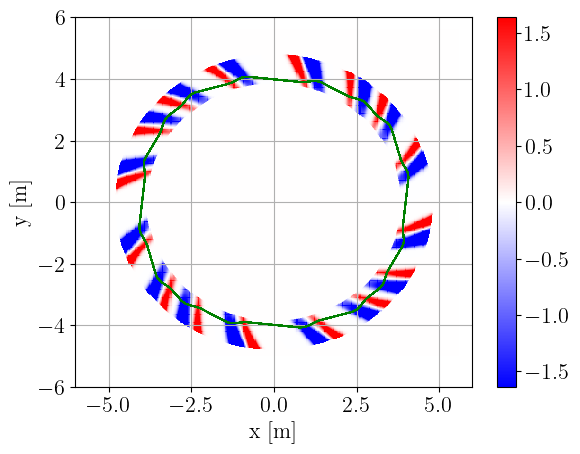

In [22]:
track_filenameFD_ffa_four_fold = "FD_ffa_four_fold" + '-trackOrbit.dat' # the particle position at each time step

trackOrbit_df = read_trackOrbit(filepath=root_path
                                , filename=track_filenameFD_ffa_four_fold)

#read the field maps
FieldMap_df = read_FieldMap(fieldmap_path, filename=fieldmap_filename)
FieldMapRPHI_df = read_FieldMapRPHI(fieldmap_path, filename=fieldmap_cyclindrical_filename)

#plot
plot_field_map_and_orbit(FieldMap_df, trackOrbit_df)

## Running OPAL in parallel with MPI

### When running lots of particles:

mpirun -np 4 !/home/carl/OPAL/build/src/opal FD_ffa_four_fold 